# 01 – Missing and Erroneous Values

**Objective:** identify and treat missing values and erroneous data in the Madrid property sales dataset, justifying every decision with evidence.

**Input:** `data/processed/listings_00.parquet` (output of notebook 00).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

# Consistent visual style
sns.set_theme(style="whitegrid", palette="colorblind", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 120, "axes.titlesize": 13, "axes.labelsize": 11})

PERIOD_MAP = {"201803": "Q1 2018", "201806": "Q2 2018", "201809": "Q3 2018", "201812": "Q4 2018"}

df = pd.read_parquet("../data/processed/listings_00.parquet")

print(f"Loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")

Loaded: 94,815 rows × 41 columns


## 1. Missing values overview

,Missing,% of total
CONSTRUCTIONYEAR,55873,58.93
FLATLOCATIONID,6387,6.74
FLOORCLEAN,3846,4.06
CADASTRALQUALITYID,1,0.00


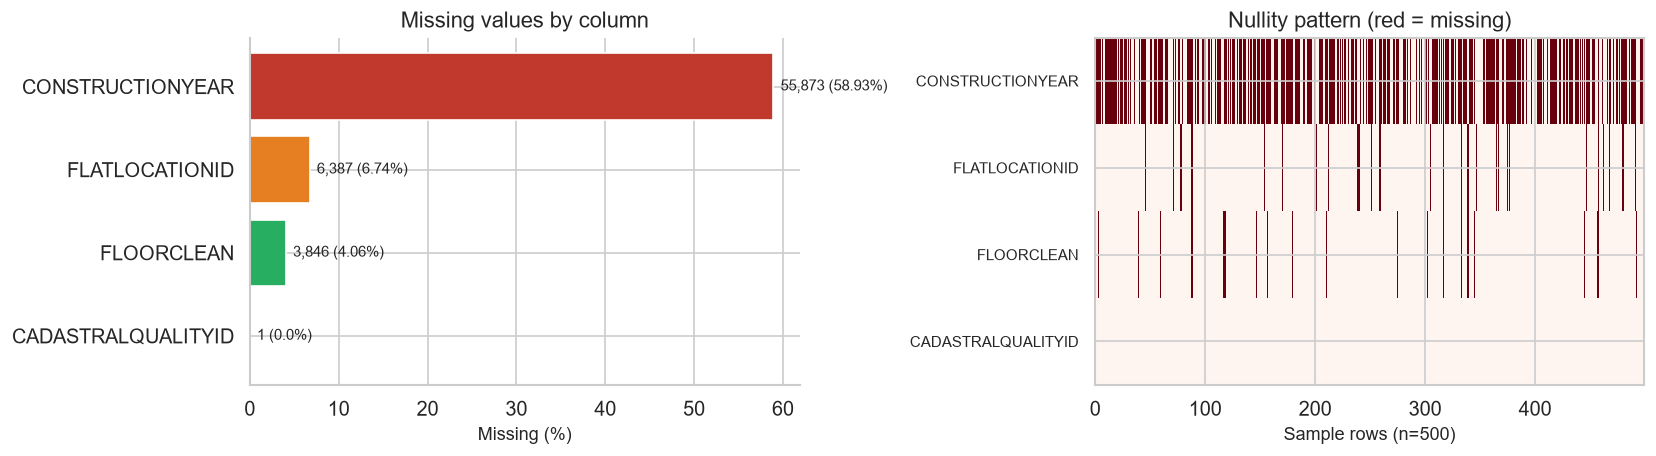

In [2]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)

missing_df = pd.DataFrame({"Missing": missing, "% of total": missing_pct})
display(missing_df)

# Visualise missing values
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: bar chart of missing percentages
severity_colors = ["#c0392c" if p > 50 else "#e67e22" if p > 5 else "#27ae60" for p in missing_pct]
bars = axes[0].barh(missing_pct.index[::-1], missing_pct.values[::-1], color=severity_colors[::-1], edgecolor="white")
axes[0].set_xlabel("Missing (%)")
axes[0].set_title("Missing values by column")
for i, (v, c) in enumerate(zip(missing_pct.values[::-1], missing.values[::-1])):
    axes[0].text(v + 0.8, i, f"{c:,} ({v}%)", va="center", fontsize=9)
axes[0].spines[["top", "right"]].set_visible(False)

# Right: heatmap of nullity for a sample
sample = df[missing.index].sample(500, random_state=42)
axes[1].imshow(sample.isnull().values.T, aspect="auto", cmap="Reds", interpolation="none")
axes[1].set_yticks(range(len(missing.index)))
axes[1].set_yticklabels(missing.index, fontsize=9)
axes[1].set_xlabel("Sample rows (n=500)")
axes[1].set_title("Nullity pattern (red = missing)")

plt.tight_layout()
plt.show()

Only 4 columns have missing values. `CONSTRUCTIONYEAR` dominates with 59% missing; the remaining three have modest gaps. The target (`PRICE`) and all binary features are 100% complete.

### 1.1 `CONSTRUCTIONYEAR` — 59% missing

This column is self-reported by the listing agent. It is missing for more than half the dataset and, as we show below, contains erroneous values. However, the cadastral alternative `CADCONSTRUCTIONYEAR` is 100% complete and comes from an official source (Spanish Cadastre).

Non-null values: 38,942 / 94,815 (41.1%)
Range: 1 – 2291

Suspicious values (year < 1800 or > 2020): 43 rows
Examples: [1692.0, 1623.0, 1623.0, 1627.0, 7.0, 1056.0, 173.0, 1780.0, 198.0, 50.0]


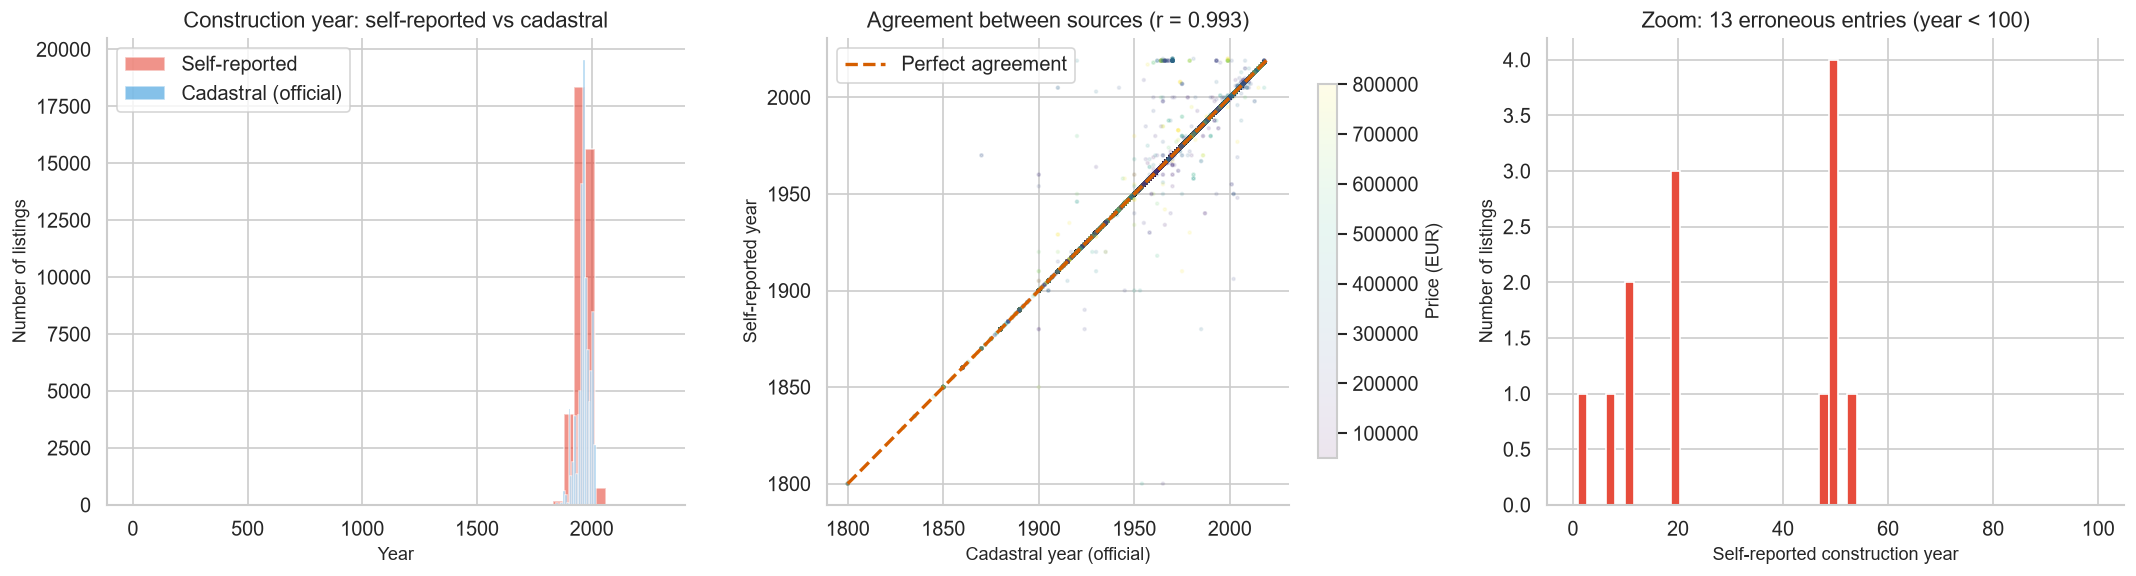


Sample rows with erroneous CONSTRUCTIONYEAR:
       CONSTRUCTIONYEAR  CADCONSTRUCTIONYEAR     PRICE  CONSTRUCTEDAREA
5220                7.0                 2008  436000.0              100
14394              50.0                 1968  302000.0              138
19510               1.0                 1977  788000.0              190
23677              54.0                 1963  762000.0              111
25971              19.0                 1930  179000.0               40
44784              10.0                 2007  773000.0              172
48169              48.0                 1971  789000.0              183
51515              10.0                 2007  762000.0              172
67495              19.0                 1930  170000.0               40
71198              50.0                 1956  559000.0              103


In [3]:
cy = df["CONSTRUCTIONYEAR"].dropna()
print(f"Non-null values: {len(cy):,} / {len(df):,} ({len(cy)/len(df):.1%})")
print(f"Range: {cy.min():.0f} – {cy.max():.0f}")

suspicious = cy[(cy < 1800) | (cy > 2020)]
print(f"\nSuspicious values (year < 1800 or > 2020): {len(suspicious)} rows")
print(f"Examples: {suspicious.head(10).tolist()}")

# Compare with cadastral year
valid = df[df["CONSTRUCTIONYEAR"].between(1800, 2020)]
corr = valid["CONSTRUCTIONYEAR"].corr(valid["CADCONSTRUCTIONYEAR"])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Distribution comparison
axes[0].hist(cy, bins=50, alpha=0.6, color="#e74c3c", label="Self-reported", edgecolor="white")
axes[0].hist(df["CADCONSTRUCTIONYEAR"], bins=50, alpha=0.6, color="#3498db", label="Cadastral (official)", edgecolor="white")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Number of listings")
axes[0].set_title("Construction year: self-reported vs cadastral")
axes[0].legend(frameon=True, fancybox=True)

# 2. Scatter: self-reported vs cadastral
scatter = axes[1].scatter(valid["CADCONSTRUCTIONYEAR"], valid["CONSTRUCTIONYEAR"],
                          c=valid["PRICE"], cmap="viridis", alpha=0.1, s=3,
                          norm=plt.Normalize(vmin=50_000, vmax=800_000))
axes[1].plot([1800, 2020], [1800, 2020], "r--", lw=2, label="Perfect agreement")
axes[1].set_xlabel("Cadastral year (official)")
axes[1].set_ylabel("Self-reported year")
axes[1].set_title(f"Agreement between sources (r = {corr:.3f})")
axes[1].legend(frameon=True)
plt.colorbar(scatter, ax=axes[1], label="Price (EUR)", shrink=0.8)

# 3. Zoom on erroneous values
axes[2].hist(cy[cy < 100], bins=30, color="#e74c3c", edgecolor="white")
axes[2].set_xlabel("Self-reported construction year")
axes[2].set_ylabel("Number of listings")
axes[2].set_title(f"Zoom: {len(cy[cy < 100])} erroneous entries (year < 100)")
axes[2].set_xlim(-5, 105)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

print("\nSample rows with erroneous CONSTRUCTIONYEAR:")
err_rows = df[df["CONSTRUCTIONYEAR"].between(0, 100, inclusive="both")]
print(err_rows[["CONSTRUCTIONYEAR", "CADCONSTRUCTIONYEAR", "PRICE", "CONSTRUCTEDAREA"]].head(10))

**Decision:** drop `CONSTRUCTIONYEAR`. The cadastral source (`CADCONSTRUCTIONYEAR`) is complete, official, and highly correlated with the valid self-reported values. Keeping the self-reported column would force us to impute 59% of the data or lose those rows.

In [4]:
df = df.drop(columns=["CONSTRUCTIONYEAR"])
print(f"Dropped CONSTRUCTIONYEAR. Shape: {df.shape}")

Dropped CONSTRUCTIONYEAR. Shape: (94815, 40)


### 1.2 `FLATLOCATIONID` — 6.7% missing

According to the official documentation of the dataset (idealista18 package), this column indicates the views of the flat: **external (1)** or **internal (2)**. Missing values likely mean the information was not provided in the listing.

In [5]:
print(df["FLATLOCATIONID"].value_counts(dropna=False))
print(f"\nMedian PRICE by FLATLOCATIONID:")
print(df.groupby("FLATLOCATIONID", dropna=False)["PRICE"].median())

FLATLOCATIONID
1.0    76324
2.0    12104
NaN     6387
Name: count, dtype: int64

Median PRICE by FLATLOCATIONID:
FLATLOCATIONID
1.0    280000.0
2.0    241000.0
NaN    173000.0
Name: PRICE, dtype: float64


External flats have a higher median price (280,000 €) than internal ones (241,000 €), as expected. Missing values have a clearly different median price (173,000 €) from both groups, so "unknown" behaves as a separate category rather than as random missingness.

**Decision:** fill `NaN` with 0 to represent "unknown". This preserves the information that the value was not reported, instead of imputing a potentially wrong category.

In [6]:
df["FLATLOCATIONID"] = df["FLATLOCATIONID"].fillna(0).astype(int)
print(df["FLATLOCATIONID"].value_counts())

FLATLOCATIONID
1    76324
2    12104
0     6387
Name: count, dtype: int64


### 1.3 `FLOORCLEAN` — 4.1% missing

The floor number of the flat. The value -1 appears 936 times and likely represents basement or ground-level commercial units.

In [7]:
print(df["FLOORCLEAN"].value_counts(dropna=False).sort_index())

missing_floor = df["FLOORCLEAN"].isna()
check_cols = ["BUILTTYPEID_1", "BUILTTYPEID_2", "BUILTTYPEID_3", "HASGARDEN", "HASSWIMMINGPOOL"]
comparison = pd.DataFrame({
    "Missing floor": df.loc[missing_floor, check_cols].mean(),
    "All listings": df[check_cols].mean(),
}).round(3)
comparison.index = ["New development", "Second hand, to restore", "Second hand, good condition",
                    "Has garden", "Has swimming pool"]
display(comparison)

print(f"Median price – missing floor: {df.loc[missing_floor, 'PRICE'].median():,.0f} € | "
      f"all listings: {df['PRICE'].median():,.0f} €")

FLOORCLEAN
-1.0       936
 0.0     10112
 1.0     20336
 2.0     17044
 3.0     14754
 4.0     11635
 5.0      6162
 6.0      3733
 7.0      2447
 8.0      1495
 9.0       814
 10.0      450
 11.0     1051
 NaN      3846
Name: count, dtype: int64


,Missing floor,All listings
New development,0.218,0.030
"Second hand, to restore",0.189,0.187
"Second hand, good condition",0.593,0.783
Has garden,0.234,0.185
Has swimming pool,0.262,0.148


Median price – missing floor: 238,000 € | all listings: 262,000 €


Floor -1 has a lower median price than floor 0, consistent with basement or semi-basement properties, so it is kept as a valid value. The value 11 is more frequent than 10 (1,051 vs 450), which suggests it groups all floors from 11 upwards.

Missing floors are **not random**: 21.8% of them are new developments, compared with 3.0% of all listings, and they have gardens and swimming pools more often. They are probably houses or new-build complexes where the advertiser did not report a floor.

**Decision:** fill missing values with the median floor (2), so the column can be used by the model, and create a new indicator `FLOOR_MISSING` (1 = floor not reported) so that this information is not lost.

In [8]:
df["FLOOR_MISSING"] = missing_floor.astype(int)
median_floor = df["FLOORCLEAN"].median()
df["FLOORCLEAN"] = df["FLOORCLEAN"].fillna(median_floor)
print(f"Created FLOOR_MISSING ({df['FLOOR_MISSING'].sum():,} listings) and filled FLOORCLEAN with median = {median_floor:.0f}")

Created FLOOR_MISSING (3,846 listings) and filled FLOORCLEAN with median = 2


### 1.4 `CADASTRALQUALITYID` — 1 missing

In [9]:
mode_quality = df["CADASTRALQUALITYID"].mode()[0]
df["CADASTRALQUALITYID"] = df["CADASTRALQUALITYID"].fillna(mode_quality)
print(f"Filled 1 missing value with mode = {mode_quality}")

Filled 1 missing value with mode = 4.0


## 2. Erroneous values

### 2.1 Extreme `ROOMNUMBER` and `BATHNUMBER`

Listings with more than 10 bedrooms or more than 5 bathrooms: 288


       ROOMNUMBER  BATHNUMBER  CONSTRUCTEDAREA      PRICE
count       288.0       288.0            288.0      288.0
mean          8.0         7.0            428.0  2342069.0
std           6.0         2.0            200.0  1609089.0
min           4.0         1.0             90.0   109000.0
25%           6.0         6.0            260.0  1197500.0
50%           6.0         6.0            400.0  1947000.0
75%           9.0         7.0            558.0  2912500.0
max          93.0        20.0            982.0  8133000.0

Share of them with more than 300 m²: 68%

Listings with less than 10 m² per bedroom: 9


,ROOMNUMBER,BATHNUMBER,CONSTRUCTEDAREA,PRICE
1645,3,0,25,119000.0
7524,3,1,25,54000.0
14134,3,1,28,80000.0
14164,3,1,28,69000.0
17638,93,2,119,450000.0
33410,3,1,28,103000.0
49815,3,1,28,59000.0
75514,6,1,55,188000.0
84059,33,2,90,109000.0


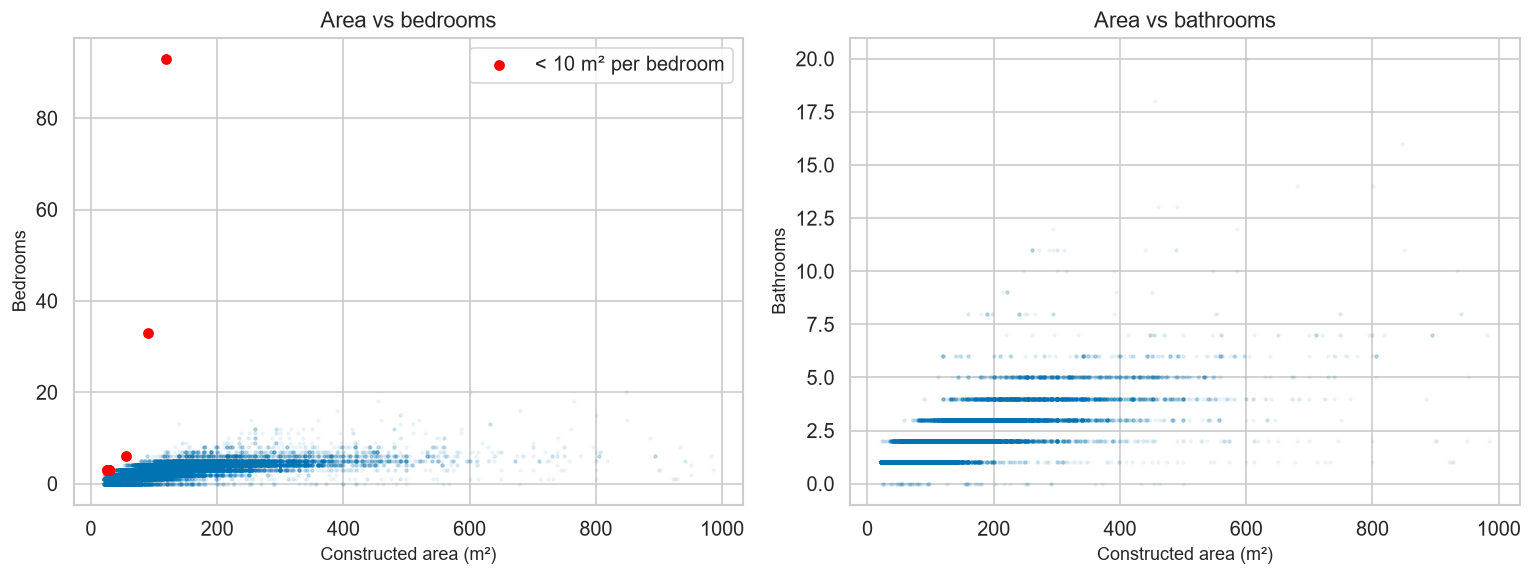

In [10]:
extreme = df[(df["ROOMNUMBER"] > 10) | (df["BATHNUMBER"] > 5)]
print(f"Listings with more than 10 bedrooms or more than 5 bathrooms: {len(extreme)}")
print(extreme[["ROOMNUMBER", "BATHNUMBER", "CONSTRUCTEDAREA", "PRICE"]].describe().round(0))
print(f"\nShare of them with more than 300 m²: {(extreme['CONSTRUCTEDAREA'] > 300).mean():.0%}")

m2_per_room = df["CONSTRUCTEDAREA"] / df["ROOMNUMBER"].replace(0, np.nan)
impossible = m2_per_room < 10
print(f"\nListings with less than 10 m² per bedroom: {impossible.sum()}")
display(df.loc[impossible, ["ROOMNUMBER", "BATHNUMBER", "CONSTRUCTEDAREA", "PRICE"]])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(df["CONSTRUCTEDAREA"], df["ROOMNUMBER"], alpha=0.05, s=3)
axes[0].scatter(df.loc[impossible, "CONSTRUCTEDAREA"], df.loc[impossible, "ROOMNUMBER"],
                color="red", s=30, label="< 10 m² per bedroom")
axes[0].set_xlabel("Constructed area (m²)")
axes[0].set_ylabel("Bedrooms")
axes[0].set_title("Area vs bedrooms")
axes[0].legend()
axes[1].scatter(df["CONSTRUCTEDAREA"], df["BATHNUMBER"], alpha=0.05, s=3)
axes[1].set_xlabel("Constructed area (m²)")
axes[1].set_ylabel("Bathrooms")
axes[1].set_title("Area vs bathrooms")
plt.tight_layout()
plt.show()

The original hypothesis (extreme values are errors in small flats) is **not supported by the data**: the 288 listings with more than 10 bedrooms or more than 5 bathrooms have a median area of 400 m² and a median price of 1.9 M€, and 68% of them are larger than 300 m². They are large luxury properties, so capping them would remove real information.

A more reliable criterion is the **area per bedroom**. Only 9 listings have less than 10 m² per bedroom (e.g. 93 bedrooms in 119 m², or 3 bedrooms in 25 m²), which is physically impossible. No listing has an implausible number of bathrooms relative to its area.

**Decision:** keep all large properties unchanged. Remove the 9 listings with an impossible number of bedrooms: their true value cannot be recovered, and they represent only 0.01% of the data.

In [11]:
n_before = len(df)
df = df[~impossible]
print(f"Removed {n_before - len(df)} listings with an impossible number of bedrooms. Shape: {df.shape}")

Removed 9 listings with an impossible number of bedrooms. Shape: (94806, 41)


### 2.2 `PARKINGSPACEPRICE` inconsistency

In [12]:
for has_parking in [0, 1]:
    s = df.loc[df["HASPARKINGSPACE"] == has_parking, "PARKINGSPACEPRICE"]
    print(f"HASPARKINGSPACE = {has_parking}: {len(s):,} listings, "
          f"{(s == 1).mean():.1%} with PARKINGSPACEPRICE = 1")
    print(s.value_counts().head(5), "\n")

HASPARKINGSPACE = 0: 73,465 listings, 97.0% with PARKINGSPACEPRICE = 1
PARKINGSPACEPRICE
1        71282
20001      230
30001      209
25001      185
15001      182
Name: count, dtype: int64 

HASPARKINGSPACE = 1: 21,341 listings, 100.0% with PARKINGSPACEPRICE = 1
PARKINGSPACEPRICE
1         21333
50001         1
15001         1
20001         1
220001        1
Name: count, dtype: int64 



`PARKINGSPACEPRICE` is uninformative **in both groups**: it equals 1 not only for listings without parking, but also for almost every listing **with** parking. The value 1 is a placeholder, not a real price, and the few other values (e.g. 20,001 or 30,001) appear where there is no parking at all. The parking information is already captured by `HASPARKINGSPACE` and `ISPARKINGSPACEINCLUDEDINPRICE`.

**Decision:** drop `PARKINGSPACEPRICE`. Setting it to 0 only for listings without parking would still leave a meaningless column.

In [13]:
df = df.drop(columns=["PARKINGSPACEPRICE"])
print(f"Dropped PARKINGSPACEPRICE. Shape: {df.shape}")

Dropped PARKINGSPACEPRICE. Shape: (94806, 40)


### 2.3 Geographic outlier

Listings with LATITUDE < 40: 1
        LATITUDE  LONGITUDE     PRICE  CONSTRUCTEDAREA
84000  36.756391  -2.753303  191000.0              145


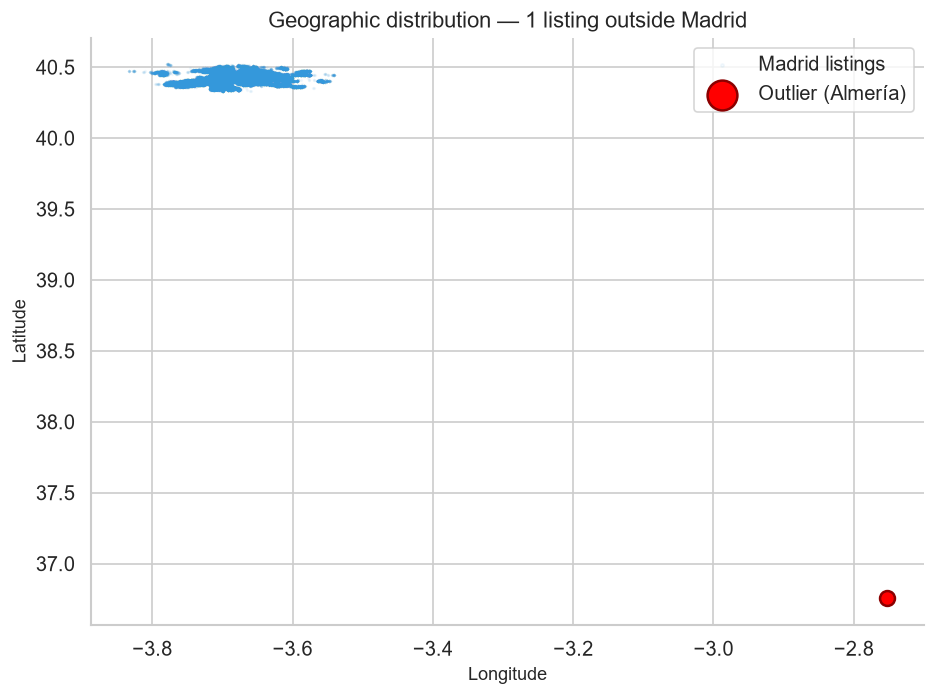

In [14]:
geo_outlier = df[df["LATITUDE"] < 40]
print(f"Listings with LATITUDE < 40: {len(geo_outlier)}")
print(geo_outlier[["LATITUDE", "LONGITUDE", "PRICE", "CONSTRUCTEDAREA"]])

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(df["LONGITUDE"], df["LATITUDE"], alpha=0.05, s=1, color="#3498db", label="Madrid listings")
ax.scatter(geo_outlier["LONGITUDE"], geo_outlier["LATITUDE"], c="red", s=80, zorder=5,
           edgecolors="darkred", linewidths=1.5, label="Outlier (Almería)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Geographic distribution — 1 listing outside Madrid")
ax.legend(frameon=True, markerscale=2)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

One listing has coordinates in Almería (latitude 36.76°), far outside Madrid (latitude ~40.4°). This is a geocoding error.

**Decision:** remove this row.

In [15]:
df = df[df["LATITUDE"] >= 40]
print(f"Removed geographic outlier. Shape: {df.shape}")

Removed geographic outlier. Shape: (94805, 40)


### 2.4 Duplicate listings

In [16]:
print(f"Total rows: {len(df):,} | unique ASSETIDs: {df['ASSETID'].nunique():,} | "
      f"repeated rows: {len(df) - df['ASSETID'].nunique():,}")
print(f"ASSETIDs appearing in more than one quarter: {(df.groupby('ASSETID')['PERIOD'].nunique() > 1).sum()}")

dups = df[df.duplicated("ASSETID", keep=False)]
g = dups.groupby("ASSETID")
same_flat = ((g["CONSTRUCTEDAREA"].nunique() == 1) & (g["ROOMNUMBER"].nunique() == 1)
             & ((g["LATITUDE"].max() - g["LATITUDE"].min()) < 0.001))
price_changes = g["PRICE"].nunique() > 1
price_spread = g["PRICE"].max() / g["PRICE"].min() - 1

print(f"\nRepeated properties: {g.ngroups:,}")
print(f"Same area, bedrooms and location: {same_flat.mean():.1%}")
print(f"With different prices: {price_changes.mean():.1%}")
print(f"Median difference between max and min price: {price_spread.median():.1%}")

sample_id = dups["ASSETID"].iloc[0]
df[df["ASSETID"] == sample_id][["ASSETID", "PERIOD", "PRICE", "CONSTRUCTEDAREA", "ROOMNUMBER", "LATITUDE", "LONGITUDE"]]

Total rows: 94,805 | unique ASSETIDs: 75,795 | repeated rows: 19,010
ASSETIDs appearing in more than one quarter: 0

Repeated properties: 13,828
Same area, bedrooms and location: 90.8%
With different prices: 97.9%
Median difference between max and min price: 4.4%


,ASSETID,PERIOD,PRICE,CONSTRUCTEDAREA,ROOMNUMBER,LATITUDE,LONGITUDE
3,A4775182175615276542,201803,284000.0,48,1,40.422251,-3.710440
3343,A4775182175615276542,201803,258000.0,45,1,40.422927,-3.710506
78832,A4775182175615276542,201803,257000.0,40,1,40.422417,-3.709864


Repeated `ASSETID`s are **the same property listed several times within the same quarter with different prices**: no property appears in more than one quarter, 90.8% of the repeated properties have the same area, bedrooms and location in all their rows, and 97.9% of them show different prices (median gap of 4.4% between the highest and lowest price). These are price updates of the same listing, not different properties.

Keeping all rows would make the model treat the same flat as several independent observations. Keeping only the first row would be arbitrary, because the order of the updates within the quarter is unknown.

**Decision:** keep one row per property and assign it the **median of its prices** in that quarter.

In [17]:
n_before = len(df)
df["PRICE"] = df.groupby("ASSETID")["PRICE"].transform("median")
df = df.drop_duplicates(subset=["ASSETID"], keep="first")
print(f"Kept one row per property with its median price. Removed {n_before - len(df):,} rows. Shape: {df.shape}")

Kept one row per property with its median price. Removed 19,010 rows. Shape: (75795, 40)


### 2.5 Target leakage: `UNITPRICE`

In [18]:
diff = (df["UNITPRICE"] - df["PRICE"] / df["CONSTRUCTEDAREA"]).abs()
print(f"Max difference between UNITPRICE and PRICE/AREA: {diff.max():.2e}")
print("UNITPRICE is exactly PRICE / CONSTRUCTEDAREA — a direct function of the target.")

df = df.drop(columns=["UNITPRICE"])
print(f"\nDropped UNITPRICE. Shape: {df.shape}")

Max difference between UNITPRICE and PRICE/AREA: 3.25e+03
UNITPRICE is exactly PRICE / CONSTRUCTEDAREA — a direct function of the target.

Dropped UNITPRICE. Shape: (75795, 39)


## Summary

**Actions performed in this notebook:**

| Issue | Evidence | Action |
|---|---|---|
| `CONSTRUCTIONYEAR` 59% missing + erroneous values | Values like 1, 50, 2291; the cadastral year is complete and official | **Dropped** (use `CADCONSTRUCTIONYEAR`) |
| `FLATLOCATIONID` 6.7% missing | Missing values have a distinct median price | Filled with 0 ("unknown") |
| `FLOORCLEAN` 4.1% missing | Not random: 21.8% new developments vs 3.0% overall | Filled with median (2) + new indicator `FLOOR_MISSING` |
| `CADASTRALQUALITYID` 1 missing | Single row | Filled with mode |
| Large properties (> 10 bedrooms or > 5 bathrooms) | Median 400 m² and 1.9 M€: real luxury properties | **Kept** (capping rejected) |
| 9 listings with < 10 m² per bedroom | Physically impossible (e.g. 93 bedrooms in 119 m²) | **Removed** |
| `PARKINGSPACEPRICE` | Equals 1 (placeholder) in 97–100% of listings, with or without parking | **Dropped** |
| 1 listing in Almería (lat. 36.76°) | Geocoding error | **Removed** |
| 19,011 repeated `ASSETID`s | Same flat, same quarter, different prices (price updates) | One row per property with its **median price** |
| `UNITPRICE` = PRICE / AREA | Direct target leakage | **Dropped** |

**Output:** 75,795 properties × 39 columns, saved to `data/processed/listings_01.parquet`.

In [19]:
import os
os.makedirs("../data/processed", exist_ok=True)
df.to_parquet("../data/processed/listings_01.parquet", index=False)
print(f"Saved: {df.shape[0]} rows × {df.shape[1]} columns")

Saved: 75795 rows × 39 columns
